In [1]:
import numpy as np
from scipy import optimize
%matplotlib widget
from dolfin import *
import matplotlib as mpl
import matplotlib.pyplot as plt
import os
from scipy.optimize import curve_fit
import pandas as pd
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
import yt

/Users/laurenyan/opt/anaconda3/envs/fungi_pde_env/lib/python3.13/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
def make_rings(data, ring_width):
    """
    From data for points in network and width of rings to divide network by, returns vertices of convex hull and concentric rings
    and radius for rings approximated as circles.
    """
    hull = ConvexHull(data)
    vertices0_index = hull.vertices
    vertices0_index = np.append(vertices0_index, vertices0_index[0])
    vertices0 = data[vertices0_index]

    rings = [vertices0]

    vertices_current = vertices0
    while Polygon(vertices_current).area > 0:
        # make rings
        buffer = shapely.buffer(Polygon(vertices_current), - ring_width).exterior.coords
        vertices_smaller = np.zeros(np.shape(vertices0))
        i = 0
        for x,y in buffer:
            vertices_smaller[i][0] = x
            vertices_smaller[i][1] = y
            i += 1
        vertices_current = vertices_smaller[~np.all(vertices_smaller == 0, axis=1)]
        rings.append(vertices_current)
    rings = rings[:-1] # remove last zero area polygon
    rings = rings[::-1]
    
    r = []
    for ring in rings:
        area = Polygon(ring).area
        r.append(np.sqrt(area / np.pi)) 

    return rings, r

In [3]:
def sigmoid_r(r, K, L, r0):
    return K / (1 + np.exp(-L * (r0 - r)))

In [4]:
def sigmoid_t(t, K, L, tn):
    return K / (1 + np.exp(L * (tn - t)))

In [5]:
def initial_pulse(r, A, s, r0):
    return A * exp(-s * abs(r - r0) ** 2)

In [6]:
def density(data, rings):
    """
    From data for points in a network and concentric rings dividing up network,
    returns density of points in each ring.
    """
    density = [0]
    
    for point in data:
        # inner most density is separate since it is not a ring
        if shapely.within(Point(point), Polygon(rings[0])):
            density[0] += 1
    density[0] /= Polygon(rings[0]).area
    
    j = 1        
    for ring in rings[1:]:
        # calculate density of each ring
        density.append(0)
        for point in data:
            if Polygon(ring).contains(Point(point)) and ~shapely.within(Point(point), Polygon(rings[j - 1])):
                density[j] += 1
        density[j] /= (Polygon(ring).area - Polygon(rings[j - 1]).area)
        j += 1
    
    return np.array(density)

In [7]:
def setup_fs_data(s_data, f_data, outf):
    s_data['split'] = 1 # 1 = yes split
    f_data['fuse'] = 1
    s_data['step_split'] = ((s_data['time_split'] / 0.25) / 400).round().astype(int) * 400
    f_data['step_fuse'] = ((f_data['time_fuse'] / 0.25) / 400).round().astype(int) * 400
    s_data['hour_split'] = (np.floor(s_data['time_split']) / (60 ** 2)).round().astype(int)
    f_data['hour_fuse'] = (np.floor(f_data['time_fuse']) / (60 ** 2)).round().astype(int)
    s_data['output_split'] = s_data['hour_split'] * 14400
    f_data['output_fuse'] = f_data['hour_fuse'] * 14400
    s_data = s_data[s_data['output_split'] < outf]
    f_data = f_data[f_data['output_fuse'] < outf]

    return s_data, f_data

In [8]:
def readin_data(run_name, data_names, outf):
    path = '/Users/laurenyan/Documents/' + run_name + '/'
    print('data from: ' + path)
    datas = {}
    
    for i in range(len(data_names)):
        ds = yt.load(path + 'plt' + data_names[i])
        doi = ds.all_data()
        dfi = doi.to_dataframe([('all', 'particle_unique_id'), ('all', 'particle_position_x'), ('all', 'particle_position_y'), ('all', 'particle_position_z'), ('all', 'particle_position'),  ('all', 'particle_cell_volume')])
        dfi = dfi.rename(columns={'particle_unique_id': 'unique_id', 'particle_position_x': 'x', 'particle_position_y': 'y', 'particle_position_z': 'z', 'particle_position': 'position', 'particle_cell_volume': 'cell_volume'})
        datas[int(data_names[i])] = dfi
    
    print(datas.keys())
    
    split_count = pd.read_csv(path + '/split_count.txt', names = ['count', 'time_split'])
    splits = pd.read_csv(path + 'splits.txt', names = ['unique_id', 'time_split'])
    fuse_count = pd.read_csv(path + 'fuse_count.txt', names = ['count', 'time_fuse'])
    fuses = pd.read_csv(path + 'fuses.txt', names = ['unique_id', 'time_fuse'])
    
    print(datas[14400].columns)

    splits, fuses = setup_fs_data(splits, fuses, outf)
    
    # data for all outputs where event occurs
    out_fs = pd.concat([fuses['output_fuse'], splits['output_split']]).unique()
    data_fs_names = [str(x) for x in out_fs]
    datas_fs = {}
    
    for i in range(len(data_fs_names)):
        ds = yt.load(path + 'plt' + data_fs_names[i])
        doi = ds.all_data()
        dfi = doi.to_dataframe([('all', 'particle_unique_id'), ('all', 'particle_position_x'), ('all', 'particle_position_y'), ('all', 'particle_position_z'), ('all', 'particle_position'),  ('all', 'particle_cell_volume')])
        dfi = dfi.rename(columns={'particle_unique_id': 'unique_id', 'particle_position_x': 'x', 'particle_position_y': 'y', 'particle_position_z': 'z', 'particle_position': 'position', 'particle_cell_volume': 'cell_volume'})
        datas_fs[int(data_fs_names[i])] = dfi
    print(datas_fs.keys())

    return datas, datas_fs, split_count, splits, fuse_count, fuses

In [9]:
def analyze_network(data_all, data_fs, fuses, splits, ring_width):
    """
    From list of data for points in network at different times and width of rings to divide network, 
    plots network at final time, tip and filament density in time and space, position of wave front, and calculates mean speed of wave front.
    """
    outf = list(data_all.keys())[-1]
    dataf = data_all[outf]
    times = [int(t) * (0.25 / 3600) for t in data_all.keys()]
    rings, rs = make_rings(dataf[['x','y']].to_numpy(), ring_width) # make rings from convex hull of final network shape
    n_rings = len(rings)
    density_tip_sum = {}
    density_in_sum = {}
    tip_r = []
    in_r = []
    ring_tip_t = []
    ring_in_t = []
    tns = []
    in_sat = []
    hr_f = int(times[-1]) # last output hour
    data_s = {}
    data_f = {}
    density_s_sum = {}
    density_f_sum = {}
    ring_s_t = []
    ring_f_t = []
    tip_pull_x = np.zeros(len(times))
    tip_pull_v = np.zeros(len(times))
    tip_all_x = np.zeros(len(times))
    tip_all_v = np.zeros(len(times))
    vdrift = np.zeros(len(times))
    vdrift_pull = np.zeros(len(times))
    xdrift_pull = np.zeros(len(times))
    l_filament = 35

    for r in range(n_rings):
        ring_tip_t.append({}) # one dictionary for each ring, will append density at each time
        ring_in_t.append({})
        ring_s_t.append({})
        ring_f_t.append({})

    dataf = data_all[outf][['x', 'y']].to_numpy()
    hullf = ConvexHull(dataf)
    tip_pull_i = hullf.vertices
    tip_pull_i = np.append(tip_pull_i, tip_pull_i[0])
    tip_pullf = dataf[tip_pull_i]
    origin = shapely.centroid(Polygon(tip_pullf))
    x0 = origin.x
    y0 = origin.y
    
    i = 0
    for out in data_all.keys():
        time = int(out * (0.25 / 3600))
        
        # sorting out split and fusion data
        if out in data_fs.keys():
            data_fs_n = data_fs[out]

            if out in fuses['output_fuse'].values:
                fuses_out = fuses[fuses['output_fuse'] == out]
                data_fs_n = data_fs_n.merge(fuses_out, on = "unique_id", how = "left")
            else:
                data_fs_n['fuse'] = np.nan
            
            if out in splits['output_split'].values:
                splits_out = splits[splits['output_split'] == out]
                data_fs_n = data_fs_n.merge(splits_out, on = "unique_id", how = "left")
            else:
                data_fs_n['split'] = np.nan
            
            data_s[out] = data_fs_n[data_fs_n['split'] == 1] # particle data of all particles that split
            data_f[out] = data_fs_n[data_fs_n['fuse'] == 1] # particle data of all particles that fuse
    
            # density in each ring
            density_s = density(data_s[out][['x','y']].to_numpy(), rings)
            density_f = density(data_f[out][['x', 'y']].to_numpy(), rings)
        else:
            density_s = [0] * n_rings
            density_f = [0] * n_rings

        q = 0
        for ring in rings:
            ring_s_t[q][time] = density_s[q]
            ring_f_t[q][time] = density_f[q]
            q += 1
        
        data = data_all[out]
        
        data = data[['x', 'y', 'position']]
        data_tip = data[data['position'] == 0]
        tip_all1 = data_tip[['x', 'y']].to_numpy()
        data_in = data[data['position'] != 0]
        data = data[['x', 'y']].to_numpy()

        # getting puller tips
        hull = ConvexHull(data)
        tip_pull_i = hull.vertices
        tip_pull_i = np.append(tip_pull_i, tip_pull_i[0])
        tip_pull1 = data[tip_pull_i]
        
        # density in each ring
        density_tip = density(data_tip[['x','y']].to_numpy(), rings)
        density_in = density(data_in[['x', 'y']].to_numpy(), rings) * l_filament
        tip_r.append(density_tip)
        in_r.append(density_in)

        k = 0
        for ring in rings:
            ring_tip_t[k][time] = density_tip[k]
            ring_in_t[k][time] = density_in[k]
            k += 1
    
        # displacement of puller tips from previous time step
        if i > 0: # can't calculate velocity in first time step
            j = 0
            for pull in tip_pull0:
                xtip = pull[0]
                ytip = pull[1]
                
                # velocity of puller tips
                distances = np.linalg.norm(tip_pull1 - pull, axis=1)
                min_index = np.argmin(distances)
                tip_pull_dx[j] = distances[min_index]
        
                # drift velocity of puller tips
                vtip = np.array([tip_pull1[min_index][0] - xtip, tip_pull1[min_index][1] - ytip])
                rtip = np.array([xtip-x0, ytip-y0])
                theta = np.dot(rtip, vtip) / (np.linalg.norm(rtip) * np.linalg.norm(vtip))
                vdrift_pull[i] += np.linalg.norm(vtip) * np.sin(theta) / 3600
                j += 1
            tip_pull_x[i] = tip_pull_x[i - 1] + np.mean(tip_pull_dx) # total displacement 
            tip_pull_v[i] = np.mean(tip_pull_dx) / 3600 # mean velocity over all tips
            vdrift_pull[i] /= len(tip_pull0)
            xdrift_pull[i] = xdrift_pull[i - 1] + vdrift_pull[i] * 3600
            
            j = 0
            for tip in tip_all0:
                xtip = tip[0]
                ytip = tip[1]
                
                # velocity of all tips
                distances = np.linalg.norm(tip_all1 - tip, axis=1)
                min_index = np.argmin(distances)
                tip_all_dx[j] = distances[min_index]
                
                # drift velocity of all tips
                vtip = np.array([tip_all1[min_index][0] - xtip, tip_all1[min_index][1] - ytip])
                rtip = np.array([xtip-x0, ytip-y0])
                theta = np.dot(rtip, vtip) / (np.linalg.norm(rtip) * np.linalg.norm(vtip))
                vdrift[i] += np.linalg.norm(vtip) * np.sin(theta) / 3600
                j += 1
            tip_all_x[i] = tip_all_x[i - 1] + np.mean(tip_all_dx) # total displacement 
            tip_all_v[i] = np.mean(tip_all_dx) / 3600 # mean velocity over all tips
            vdrift[i] /= len(tip_all0)
        
        i += 1   
        tip_pull0 = tip_pull1 # saving tips to calculate velocity at next time
        tip_all0 = tip_all1
        tip_pull_dx = np.zeros(len(tip_pull0))
        tip_all_dx = np.zeros(len(tip_all0))

    # fig4, ax4 = plt.subplots(figsize = (8,8))
    # for ring in rings:
        # ax4.plot(ring[:, 0], ring[:, 1], 'r--', lw = 1)
    # ax4.scatter(data_tip['x'].to_numpy(), data_tip['y'].to_numpy(), marker = 's')
    # ax4.scatter(data_in['x'].to_numpy(), data_in['y'].to_numpy(), marker = 's')
    # ax4.set_title('final network')
    # ax4.legend()
    # ax4.set_xlabel('x(cm)')
    # ax4.set_ylabel('y(cm)')
    
    # fitting sigmoid curve to filament density over time of each ring
    ring_in_t_fit = []
    omit_ring = [] # omit these rings for all averages over rings and with shifted time
    p = 0
    for ring in ring_in_t:
        try:
            ring_t = np.array(list(ring.values()))
            p0 = [np.max(ring_t), np.min(times), np.median(times)] # initial guess
            popt, pcov = curve_fit(sigmoid_t, times, ring_t, p0) # best fit parameters and covariance
            if popt[1] < 0:
                omit_ring.append(p)
                tns.append(0)
            else:
                tns.append(np.floor(popt[2]))
                in_sat.append(popt[0])
                ring_in_t_fit.append(sigmoid_t(times, popt[0], popt[1], popt[2]))
        
        except RuntimeError as e:
            omit_ring.append(p)
            tns.append(0)

    t0 = 0 # int(times[-1] / 3)
    r0 = np.nonzero(tip_r[t0])[0][0]
            
    shifted_t = np.arange(-int(times[-1] - tns[r0]), int(times[-1] - tns[r0]))

    # ax4.plot(rings[r0][:, 0], rings[r0][:, 1], 'g--', lw = 1)
    
    # make dictionary with keys for shifted time
    for t in shifted_t:
        density_s_sum[t] = 0
        density_f_sum[t] = 0

    # calculating mean density of each ring at shifted time
    m = r0
    for ring_s, ring_f in zip(ring_s_t[r0:], ring_f_t[r0:]):
        if m not in omit_ring:
            tn = tns[m] # time to shift by
            for t in density_s_sum.keys():
                if t + tn in ring_s.keys():
                    density_s_sum[t] += ring_s[t + tn]
                else:
                    density_s_sum[t] += 0 # no data for this time, so network has not arrived there yet
            
            for t in density_f_sum.keys():
                if t + tn in ring_f.keys():
                    density_f_sum[t] += ring_f[t + tn]
                else:
                    density_f_sum[t] += 0
        m += 1

    density_s_mean = [x / (n_rings - r0) for x in list(density_s_sum.values())]
    density_f_mean = [x / (n_rings - r0) for x in list(density_f_sum.values())]
    
    # make dictionary with keys for shifted time
    for t in shifted_t:
        density_tip_sum[t] = 0
        density_in_sum[t] = 0

    # calculating mean density of each ring at shifted time
    m = r0
    for ring_tip, ring_in in zip(ring_tip_t[r0:], ring_in_t[r0:]):
        if m not in omit_ring:
            tn = tns[m] # time to shift by
            for t in density_tip_sum.keys():
                if t + tn in ring_tip.keys():
                    density_tip_sum[t] += ring_tip[t + tn]
                else:
                    density_tip_sum[t] += 0 # no data for this time, so network has not arrived there yet
            
            for t in density_in_sum.keys():
                if t + tn in ring_in.keys():
                    density_in_sum[t] += ring_in[t + tn]
                elif ((t + tn) > np.array(list(ring_in.keys()))).all(): # after the network passes through the ring the density is constant
                    density_in_sum[t] += ring_in[np.max(list(ring_in.keys()))]
                else:
                    density_in_sum[t] += 0
        m += 1

    density_tip_mean = [x / (n_rings - r0) for x in list(density_tip_sum.values())]
    density_in_mean = [x / (n_rings - r0) for x in list(density_in_sum.values())]

    res = stats.linregress(density_tip_mean, density_s_mean)
    alpha = res.slope
    intercept_alpha = res.intercept
    n = np.array(density_tip_mean)
    alphan = np.array(density_tip_mean) * alpha
    b = np.array(density_s_mean)
    
    res = stats.linregress(np.array(density_tip_mean) * np.array(density_in_mean), density_f_mean)
    beta = res.slope
    intercept_beta = res.intercept
    nrho = np.array(density_tip_mean) * np.array(density_in_mean)
    betanrho = np.array(density_tip_mean) * np.array(density_in_mean) * beta
    a = np.array(density_f_mean)

    res = stats.linregress(times, xdrift_pull)
    vd = res.slope / 3600 # mm/hr
    sg = np.mean(tip_pull_v[1:]) * 36000 # mm/hr

    tip_init = tip_r[0]

    return tip_r, in_r, xdrift_pull, rs, r0, t0, shifted_t, alpha, intercept_alpha, n, alphan, b, beta, intercept_beta, nrho, betanrho, a, vd, sg, tip_init

In [10]:
def rho_c(tip_r, in_r, rs, time, r0, t0):
    times = np.arange(t0, time)
    rho_max_t = []
    wavefront_t = []

    # fig1, axs = plt.subplots(1, 2, figsize = (12, 6))
    for t in times:
        if (tip_r[t][r0:] > 0).any():
            t0 = t
            times = np.arange(t0, time)
            break
    
    for t in times:
        in_r_t = in_r[t][r0:]
        tip_r_t = tip_r[t][r0:]
        try:
            p0 = [np.max(in_r_t) / 100000, 1, np.median(rs[r0:]) * 100] # initial guess 
            popt, pcov = curve_fit(sigmoid_r, np.array(rs[r0:]) * 100, np.array(in_r_t) / 100000, p0) # best fit parameters and covariance
            # axs[1].plot(np.array(rs[r0:]) * 100, sigmoid_r(np.array(rs[r0:]) * 100, np.max(in_r)/ 100000, np.min(rs[r0:]) * 100, np.median(rs[r0:]) * 100), label = 'initial guess')
            if (popt[0] > np.max(in_r_t) / 100000) or (popt[0] < 0) or (popt[1] < 0):
                rho_max = np.max(in_r_t / 100000)
                # print(density_sat)
                # print(popt[2])
                # axs[0].plot(np.array(rs[r0:]) * 100, in_r_t / 100000) # across all rings from r
                # axs[0].hlines(rho_max, rs[r0] * 100, rs[-1] * 100, linestyle = '--', color = 'r')
            else:
                rho_max = popt[0]
                # print(density_sat)
                # print(popt[2])
                # axs[1].plot(np.array(rs[r0:]) * 100, sigmoid_r(np.array(rs[r0:]) * 100, popt[0], popt[1], popt[2]), 'r', label = 'best fit')
                # axs[1].vlines(popt[2], 0, np.max(in_r_t) / 100000, linestyle = '--')
                # axs[1].hlines(popt[0], rs[r0] * 100, rs[-1] * 100, linestyle = '--', color = 'g')
                # axs[0].plot(np.array(rs[r0:]) * 100, in_r_t / 100000) # across all rings from r
                # axs[0].vlines(popt[2], 0, np.max(in_r_t) / 100000, linestyle = '--')
                # axs[0].hlines(popt[0], rs[r0] * 100, rs[-1] * 100, linestyle = '--', color = 'g')
        except RuntimeError as e:
            # axs[0].plot(np.array(rs[r0:]) * 100, in_r_t / 100000)
            rho_max = np.max(in_r_t) / 100000
            # print(density_sat)
            # axs[0].hlines(rho_max, rs[r0] * 100, rs[-1] * 100, linestyle = '--', color = 'b')
            # axs[1].hlines(rho_max, rs[r0] * 100, rs[-1] * 100, linestyle = '--', color = 'b')
            print('hour ' + str(t))
            print(e)
        rho_max_t.append(rho_max)
        # try:
        #     p0 = [np.max(in_r_t)/ 100000, 1, np.median(rs[r0:]) * 100] # initial guess 
        #     popt, pcov = curve_fit(sigmoid_r, np.array(rs[r0:]) * 100, np.array(in_r_t) / 100000, p0) # best fit parameters and covariance
        #     if popt[0] > np.max(in_r_t) / 100000:
        #         rho_max = np.max(in_r_t / 100000)
        #     else:
        #         rho_max = popt[0]
        # except RuntimeError as e:
        #     rho_max = np.max(in_r_t) / 100000
        #     print('hour ' + str(t))
        #     print(e)
        
        # rho_max_t.append(rho_max)

        try:
            wavefront = rs[r0:][np.argmax(tip_r_t)]
        except IndexError:
            wavefront = rs[r0:][-1]

        wavefront_t.append(wavefront)

    return np.array(rho_max_t) * 100000 * 1e-5, np.array(wavefront_t)

In [11]:
def ABM(run_names, outf, ring_width):
    '''
    run_names = list of names of sets of plt files for each run stored in /Users/laurenyan/Documents/ 
    (ex. ['bmxdefault_0', 'bmxdefault_1'])
    outf = last output number of data
    Returns average and standard deviation over all runs in time. 
    '''
    out0 = 14400
    dout = 14400 # get data for each hour
    outs = np.arange(out0, outf, dout)
    data_names = [str(x) for x in outs]
    time = len(data_names) # hours

    datas = []
    datas_fs = []
    splits = []
    fuses = []
    split_counts = []
    fuse_counts = []
    outputs = []
    rho_maxs = []
    wavefronts = []
    xdrifts = []
    alpha0 = 0
    beta0 = 0
    v_sval0 = 0
    s_scal0 = 0

    i = 0 # run number
    for run in run_names:
        print('run ' + str(i) + ':')
        datai, data_fsi, split_counti, splitsi, fuse_counti, fusesi = readin_data(run, data_names, outf)
        # tip_r, in_r, xdrift_pull, rs, r0, t0, shifted_t, alpha, intercept_alpha, n, alphan, b, beta, intercept_beta, nrho, betanrho, a 
        outputi = analyze_network(datai, data_fsi, fusesi, splitsi, ring_width)
        r0 = outputi[4]
        t0 = outputi[5]
        alpha0 += outputi[7]
        beta0 += outputi[12]
        v_sval0 += outputi[17]
        s_scal0 += outputi[18]
        pulse0 = outputi[19]
        
        rm, wf = rho_c(outputi[0], outputi[1], outputi[3], time, r0, t0)
        xd = outputi[2]
        rho_maxs.append(rm)
        wavefronts.append(wf)
        xdrifts.append(xd)

        i += 1

    alpha0 /= i
    beta0 /= i
    v_sval0 /= i
    s_scal0 /= i
    
    rm_mean = np.mean(np.vstack(rho_maxs), axis = 0)
    rm_std = np.std(np.vstack(rho_maxs), axis =0)
    c_wf_mean = np.mean(np.vstack(wavefronts), axis = 0)
    c_wf_std = np.std(np.vstack(wavefronts), axis =0)
    c_xd_mean = np.mean(np.vstack(xdrifts), axis = 0)[t0:]
    c_xd_std = np.std(np.vstack(xdrifts), axis =0)[t0:]

    times = np.arange(t0, time)
    # fig1, ax1 = plt.subplots()
    # ax1.plot(times, rm_mean)
    # ax1.fill_between(times, rm_mean - rm_std, rm_mean + rm_std, alpha = 0.3)
    # for rm in rho_maxs:
        # ax1.scatter(times, rm)

    # two ways of determining wave speed
    # fitting to filament density to find wavefront position
    # fig2, ax2 = plt.subplots()
    res = stats.linregress(times, c_wf_mean)
    # ax2.plot(times, times * res.slope + res.intercept)
    # ax2.fill_between(times, wf_mean - wf_std, wf_mean + wf_std, alpha = 0.3)
    # for wf in wavefronts:
    #     ax2.scatter(times, wf)

    # "drift position" of hyphae
    # fig3, ax3 = plt.subplots()
    res = stats.linregress(times, c_xd_mean)
    # ax3.plot(times, times * res.slope + res.intercept)
    # ax3.plot(times, xd_mean)
    # ax3.fill_between(times, xd_mean - xd_std, xd_mean + xd_std, alpha = 0.3)
    # for xd in xdrifts:
    #     ax3.scatter(times, xd[t0:])

    c = res.slope
    D0 = (((c - v_sval0) / 2) ** 2) * (1 / alpha0)
    
    return rm_mean, c_xd_mean, c_wf_mean, rm_std, c_xd_std, c_wf_std, alpha0, beta0, v_sval0, s_scal0, D0

In [12]:
z1 = ABM(['bmx_default0', 'bmx_default1', 'bmx_default2'], 500000, 0.0008)

run 0:
data from: /Users/laurenyan/Documents/bmx_default0/


yt : [INFO     ] 2026-01-09 13:18:12,313 Parameters: current_time              = 3600.0
yt : [INFO     ] 2026-01-09 13:18:12,315 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:18:12,316 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-01-09 13:18:12,319 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-01-09 13:18:12,609 Parameters: current_time              = 7200.0
yt : [INFO     ] 2026-01-09 13:18:12,610 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:18:12,611 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-01-09 13:18:12,611 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-01-09 13:18:12,785 Parameters: current_time              = 10800.0
yt : [INFO     ] 2026-01-09 13:18:12,786 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:18:12,787 Parameters: domain_left_edge          = [0. 

dict_keys([14400, 28800, 43200, 57600, 72000, 86400, 100800, 115200, 129600, 144000, 158400, 172800, 187200, 201600, 216000, 230400, 244800, 259200, 273600, 288000, 302400, 316800, 331200, 345600, 360000, 374400, 388800, 403200, 417600, 432000, 446400, 460800, 475200, 489600])
Index(['unique_id', 'x', 'y', 'z', 'position', 'cell_volume'], dtype='object')


yt : [INFO     ] 2026-01-09 13:18:20,126 Parameters: current_time              = 32400.0
yt : [INFO     ] 2026-01-09 13:18:20,127 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:18:20,128 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-01-09 13:18:20,129 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-01-09 13:18:20,314 Parameters: current_time              = 43200.0
yt : [INFO     ] 2026-01-09 13:18:20,315 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:18:20,316 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-01-09 13:18:20,317 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-01-09 13:18:20,500 Parameters: current_time              = 75600.0
yt : [INFO     ] 2026-01-09 13:18:20,501 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:18:20,502 Parameters: domain_left_edge          = [0

dict_keys([100800, 129600, 172800, 302400, 316800, 331200, 345600, 360000, 374400, 388800, 403200, 417600, 432000, 446400, 460800, 475200, 489600, 43200, 57600, 72000, 115200, 158400, 216000, 230400, 244800, 259200, 273600, 288000])


/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_69167/1422531783.py:2: RuntimeWarning: overflow encountered in exp
  return K / (1 + np.exp(-L * (r0 - r)))
yt : [INFO     ] 2026-01-09 13:19:02,109 Parameters: current_time              = 3600.0
yt : [INFO     ] 2026-01-09 13:19:02,112 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:19:02,114 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-01-09 13:19:02,115 Parameters: domain_right_edge         = [0.2 0.2 0.1]


... (8 outputs left out)

dict_keys([14400, 28800, 43200, 57600, 72000, 86400, 100800, 115200, 129600, 144000, 158400, 172800, 187200, 201600, 216000, 230400, 244800, 259200, 273600, 288000, 302400, 316800, 331200, 345600, 360000, 374400, 388800, 403200, 417600, 432000, 446400, 460800, 475200, 489600])
Index(['unique_id', 'x', 'y', 'z', 'position', 'cell_volume'], dtype='object')


yt : [INFO     ] 2026-01-09 13:20:23,375 Parameters: current_time              = 32400.0
yt : [INFO     ] 2026-01-09 13:20:23,382 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:20:23,382 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-01-09 13:20:23,384 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-01-09 13:20:23,556 Parameters: current_time              = 39600.0
yt : [INFO     ] 2026-01-09 13:20:23,557 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:20:23,557 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-01-09 13:20:23,558 Parameters: domain_right_edge         = [0.2 0.2 0.1]
yt : [INFO     ] 2026-01-09 13:20:23,889 Parameters: current_time              = 54000.0
yt : [INFO     ] 2026-01-09 13:20:23,890 Parameters: domain_dimensions         = [16 16  8]
yt : [INFO     ] 2026-01-09 13:20:23,890 Parameters: domain_left_edge          = [0

dict_keys([100800, 129600, 158400, 216000, 244800, 259200, 273600, 288000, 302400, 331200, 345600, 360000, 374400, 388800, 403200, 432000, 446400, 460800, 475200, 489600, 43200, 57600, 72000, 115200, 144000, 187200, 201600, 230400, 316800, 417600])
hour 0
Optimal parameters not found: Number of calls to function has reached maxfev = 800.


/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_69167/3874421281.py:179: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(sigmoid_t, times, ring_t, p0) # best fit parameters and covariance
/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_69167/4248635890.py:2: RuntimeWarning: overflow encountered in exp
  return K / (1 + np.exp(L * (tn - t)))


In [24]:
def PDE(pars, time):
    '''
    time = hours
    '''
    alphval = pars[0]
    beta = Constant(pars[1])
    v_sval = pars[2]
    s_scal = Constant(pars[3])
    D = Constant(pars[4])
    
    # Define the problem
    Length = 1.0 # 40.0
    left = 1e-3
    nx = 100
    nT = int(time * 10) # 900
    keep = 10 # get every hour
    mesh = IntervalMesh(nx, left, Length)
    P1 = FiniteElement('P', interval, 1)
    element = MixedElement([P1, P1])
    V = FunctionSpace(mesh, element)
    cmap2 = mpl.colormaps["spring"]
    cmap = mpl.colormaps["winter"]
    
    density_tip = np.zeros((int(nT / keep), nx))
    density_in = np.zeros((int(nT / keep), nx))
    
    # Define the parameters
    T = time # 90
    dt = T/nT
    # alphval = 0.039
    cval = 0.6
    # Define the initial condition
    u0 = Expression(('100*exp(-500*pow(x[0]-0.1,2))', '0.0'), degree=1) # Expression(('0.8*exp(-0.1*pow(abs(x[0]-7),2))',0), degree=1)
    #define radial coordinate
    rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
    r = interpolate(rexp, V)
    invr, _ = split(r)
    # Define other elements
    
    u_n = interpolate(u0, V)
    u = Function (V)
    n, rho = split(u)
    n_n, rho_n= split(u_n)
    v_1, v_2 = TestFunctions(V)
    k = Constant((1,))
    
    # s_scal =  Constant(0.0288) # Constant(0.2)
    # beta = Constant(0.022)
    alpha = Constant(alphval)
    # D = Constant(0.02)
    
    n_mid = 0.5*(n_n + n)
    # v_sval = 0.235
    v_s = Constant((v_sval,))
    
    F = n*v_1*dx - n_n*v_1*dx 
    #Diffusion coefficient
    F += D*dot(grad(n), grad(v_1))*dt*dx
    # To account for cylindrical coordinates
    F += invr*D*dot(grad(n), Constant((1,)))*v_1*dt*dx
    F += dt*dot(grad(n_mid),v_s)*v_1*dx
    # To account for cylindrical coordinates
    F += invr*dt*n_mid*Constant(v_sval)*v_1*dx
    
    F -=dt*s_scal*n*v_2*dx-(rho-rho_n)*v_2*dx
    F += beta*v_1*rho*(n)*dt*dx
    F -= alpha*(n)*v_1*dt*dx
    
    # Apply the boundary conditions
    u_L = (Constant(0.0),Constant(0.0))
    u_R = (Constant(0.0),Constant(0.0))
    bc_L = DirichletBC(V, u_L, 'near(x[0], 1.0)')
    bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
    bcs = [bc_L, bc_R]
    
    # bc = PeriodicBC(V, Boundary())# Solve the problem
    t = 0.0
    a, L = lhs(F), rhs(F)
    V2 = FunctionSpace(mesh, 'P', 1)
    X = np.linspace(left,Length,nx)
    poss = []
    
    i=0
    # fig, axs = plt.subplots(3, 1)
    for t in np.linspace(0,T,nT):
        try:
            solve(F==0, u,bcs)
            u_n.assign(u)
            _n, _rho= u.split()
        
            if i%keep==0:# i%100==0:
                n_field = interpolate(_n, V2)
                rho_field = interpolate(_rho, V2)
                density_tip[int(i / keep), :] = [n_field(x) for x in X]
                density_in[int(i / keep), :] = [rho_field(x) for x in X]
                poss.append(np.argmax([n_field(x) for x in X]))

                # axs[0].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
                # axs[1].plot(X, [rho_field(x) for x in X], color=cmap(t / T))
                
        except RuntimeError as e:
            print('hour ' + str(t))
            print(e)
            if i%keep==0:# i%100==0:
                density_tip[int(i / keep), :] = np.zeros(len(X))
                density_in[int(i / keep), :] = np.zeros(len(X))
                poss.append(0)
        i += 1
    
    out_dx = np.array(poss)*Length/nx
    
    rho_sat = []
    
    for t in np.arange(T):
        # collect PDE output for each hour

        # saturation density
        to_fit_in = density_in[t, :]
        to_fit_tip = density_tip[t, :]
        cs = CubicSpline(X, to_fit_in)

        for j in range(len(X)):
            if cs(X, 1)[j] < 0 and cs(X, 1)[j-1] > 0:
                cutoff = j
                break
            else:
                cutoff = 0
        try:
            K_guess = np.max(to_fit_in[cutoff:])
            L_guess = np.max(X)
            r0_guess = np.median(X[cutoff:])
            p0_sig = [K_guess, L_guess, r0_guess] # initial guess 
            popt_sig, pcov_sig = curve_fit(sigmoid_r, X[cutoff:], to_fit_in[cutoff:], p0_sig)
            if popt_sig[0] > np.max(to_fit_in):
                density_sat = np.max(to_fit_in)
            else:
                density_sat = popt_sig[0]
        except RuntimeError as e:
            density_sat = np.max(to_fit_in)
            print('hour ' + str(t))
            print(e)

        rho_sat.append(density_sat)
        
    return out_dx, np.array(rho_sat)

In [25]:
def get_res(pars, start, time, z, out_mode):
    ''' 
    time = hours
    pars = parameters of PDE to optimize about
    z = ABM output for each hour except 0
    mode = 1 to fit for wave speed
    mode = 0 to fit for saturation density
    '''
    print(pars)
    c, rho_sat = PDE(pars, time)
    if out_mode == 0:
        y = rho_sat
    if out_mode == 1:
        y = c
        
    return np.array([(z[i] -  y[i - 1]) ** 2 for i in range(start,time)])

In [26]:
def err_func(pars, start, time, z, out_mode, wts):
    '''
    wts = (1/s)^2 where s is variance of ABM output
    '''
    res = get_res(pars, start, time, z, out_mode)
    return np.sum(res * wts)

In [27]:
alpha_init = z1[6]
beta_init = z1[7]
v_sval_init = z1[8]
s_scal_init = z1[9]
D_init = z1[10]
start = 0
time = 34
out_mode = 1
par_init = [alpha_init, beta_init, v_sval_init, s_scal_init, D_init]
bnds = ((0, None), (0, None), (0, None), (0, None), (0, None))

# wts from ABM data
z_var = z1[out_mode][start:]
wts = np.array([(1 / s) ** 2 for s in z_var])

popt = optimize.minimize(err_func, x0=par_init, args=(start, time, z1[out_mode], out_mode, wts, ), bounds = bnds)
err = err_func(popt.x, start, time, z1[out_mode], out_mode, wts, )

[1.84186060e-01 7.17205504e-08 5.60309032e-07 2.92656500e-02
 5.51953118e-06]
Form has no parts with arity 2.


/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_69167/3626139912.py:14: RuntimeWarning: divide by zero encountered in scalar divide
  wts = np.array([(1 / s) ** 2 for s in z_var])


[1.84186070e-01 7.17205504e-08 5.60309032e-07 2.92656500e-02
 5.51953118e-06]
Form has no parts with arity 2.
[1.84186060e-01 8.17205504e-08 5.60309032e-07 2.92656500e-02
 5.51953118e-06]
Form has no parts with arity 2.
[1.84186060e-01 7.17205504e-08 5.70309032e-07 2.92656500e-02
 5.51953118e-06]
Form has no parts with arity 2.
[1.84186060e-01 7.17205504e-08 5.60309032e-07 2.92656600e-02
 5.51953118e-06]
Form has no parts with arity 2.
[1.84186060e-01 7.17205504e-08 5.60309032e-07 2.92656500e-02
 5.52953118e-06]
Form has no parts with arity 2.
[nan nan nan nan nan]
Form has no parts with arity 2.
hour 0.0


*** -------------------------------------------------------------------------
*** DOLFIN encountered an error. If you are not able to resolve this issue
*** using the information listed below, you can ask for help at
***
***     fenics-support@googlegroups.com
***
*** Remember to include the error message listed below and, if possible,
*** include a *minimal* running example to repr

/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_69167/2877942259.py:133: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_sig, pcov_sig = curve_fit(sigmoid_r, X[cutoff:], to_fit_in[cutoff:], p0_sig)
/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_69167/1765834634.py:6: RuntimeWarning: invalid value encountered in multiply
  return np.sum(res * wts)





*** -------------------------------------------------------------------------
*** DOLFIN encountered an error. If you are not able to resolve this issue
*** using the information listed below, you can ask for help at
***
***     fenics-support@googlegroups.com
***
*** Remember to include the error message listed below and, if possible,
*** include a *minimal* running example to reproduce the error.
***
*** -------------------------------------------------------------------------
*** Error:   Unable to solve nonlinear system with NewtonSolver.
*** Reason:  Newton solver did not converge because maximum number of iterations reached.
*** Where:   This error was encountered inside NewtonSolver.cpp.
*** Process: 0
*** 
*** DOLFIN version: 2019.1.0
*** Git changeset:  
*** -------------------------------------------------------------------------

hour 0.40117994100294985


*** -------------------------------------------------------------------------
*** DOLFIN encountered an error. If you

KeyboardInterrupt: 

Form has no parts with arity 2.
No Jacobian form specified for nonlinear variational problem.
Differentiating residual form F to obtain Jacobian J = F'.
Solving nonlinear variational problem.
  Newton iteration 0: r (abs) = 2.347e+00 (tol = 1.000e-10) r (rel) = 1.000e+00 (tol = 1.000e-09)
  Newton iteration 1: r (abs) = 2.874e-09 (tol = 1.000e-10) r (rel) = 1.224e-09 (tol = 1.000e-09)
  Newton iteration 2: r (abs) = 1.198e-16 (tol = 1.000e-10) r (rel) = 5.103e-17 (tol = 1.000e-09)
  Newton solver finished in 2 iterations and 2 linear solver iterations.
No Jacobian form specified for nonlinear variational problem.
Differentiating residual form F to obtain Jacobian J = F'.
Solving nonlinear variational problem.
  Newton iteration 0: r (abs) = 2.825e-02 (tol = 1.000e-10) r (rel) = 1.000e+00 (tol = 1.000e-09)
  Newton iteration 1: r (abs) = 3.255e-11 (tol = 1.000e-10) r (rel) = 1.152e-09 (tol = 1.000e-09)
  Newton solver finished in 1 iterations and 1 linear solver iterations.
No Jacobian 

er iterations.
No Jacobian form specified for nonlinear variational problem.
Differentiating residual form F to obtain Jacobian J = F'.
Solving nonlinear variational problem.
  Newton iteration 0: r (abs) = 3.405e+01 (tol = 1.000e-10) r (rel) = 1.000e+00 (tol = 1.000e-09)
  Newton iteration 1: r (abs) = 5.982e-05 (tol = 1.000e-10) r (rel) = 1.757e-06 (tol = 1.000e-09)
  Newton iteration 2: r (abs) = 7.976e-14 (tol = 1.000e-10) r (rel) = 2.342e-15 (tol = 1.000e-09)
  Newton solver finished in 2 iterations and 2 linear solver iterations.
No Jacobian form specified for nonlinear variational problem.
Differentiating residual form F to obtain Jacobian J = F'.
Solving nonlinear variational problem.
  Newton iteration 0: r (abs) = 3.523e+01 (tol = 1.000e-10) r (rel) = 1.000e+00 (tol = 1.000e-09)
  Newton iteration 1: r (abs) = 6.403e-05 (tol = 1.000e-10) r (rel) = 1.818e-06 (tol = 1.000e-09)
  Newton iteration 2: r (abs) = 8.623e-14 (tol = 1.000e-10) r (rel) = 2.448e-15 (tol = 1.000e-09)
  Ne

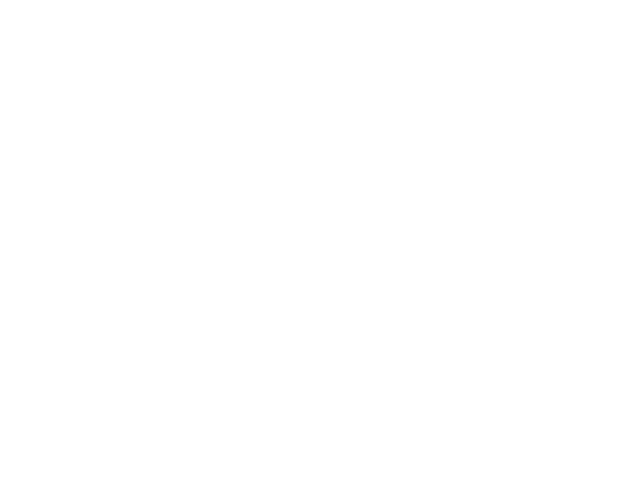

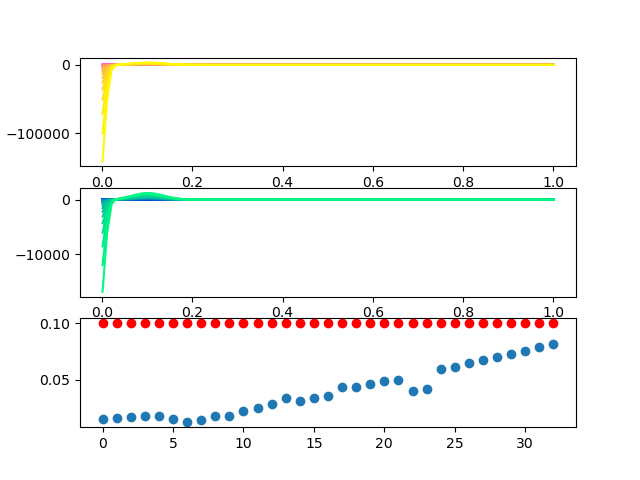

In [16]:
pars = [0.115, 3.586e-08, 2.802e-07, 0.0402, 5.519e-06]
plt.scatter(np.arange(33), PDE(pars, 33)[0] , color ='r')
plt.scatter(np.arange(33), z1[2][1:])